<a href="https://colab.research.google.com/github/ANSR1226/epoch-gym/blob/main/heart_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [ ]:
import os

In [ ]:
import kagglehub
path = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.


In [ ]:
f_path = os.path.join(path, 'heart.csv')

In [ ]:
f_path

'/kaggle/input/heart-disease-dataset/heart.csv'

In [ ]:
keras.utils.set_random_seed(42)

In [ ]:
df = pd.read_csv(f_path)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
df['thal'].value_counts()

,count
thal,
2,544
3,410
1,64
0,7


In [ ]:
cat_col = ['sex','cp','fbs','restecg','exang','slope','ca','thal']
num_col = ['age', 'trestbps', 'chol','thalach','oldpeak']
target = ['target']

One-Hot encoding categorical columns because Neural Network can't really handle categorical columns well.

In [ ]:
df = pd.get_dummies(df, columns = cat_col)

In [ ]:
df = df.astype(float)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 31 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        1025 non-null   float64
 1   trestbps   1025 non-null   float64
 2   chol       1025 non-null   float64
 3   thalach    1025 non-null   float64
 4   oldpeak    1025 non-null   float64
 5   target     1025 non-null   float64
 6   sex_0      1025 non-null   float64
 7   sex_1      1025 non-null   float64
 8   cp_0       1025 non-null   float64
 9   cp_1       1025 non-null   float64
 10  cp_2       1025 non-null   float64
 11  cp_3       1025 non-null   float64
 12  fbs_0      1025 non-null   float64
 13  fbs_1      1025 non-null   float64
 14  restecg_0  1025 non-null   float64
 15  restecg_1  1025 non-null   float64
 16  restecg_2  1025 non-null   float64
 17  exang_0    1025 non-null   float64
 18  exang_1    1025 non-null   float64
 19  slope_0    1025 non-null   float64
 20  slope_1 

**SPLITTLING DATA**

In [ ]:
test_df = df.sample(frac=0.2, random_state = 42)
train_df = df.drop(test_df.index) #index means ROW INDICES of the data of test_df

In [ ]:
mean = train_df[num_col].mean()
sd = train_df[num_col].std()

STANDARDIZATION OF DATA

In [ ]:
train_df[num_col] = (train_df[num_col] - mean)/sd
test_df[num_col] = (test_df[num_col] - mean)/sd

In [ ]:
train = train_df.to_numpy()
test = test_df.to_numpy()

In [ ]:
train_df.head()

,age,trestbps,chol,thalach,oldpeak,target,sex_0,sex_1,cp_0,cp_1,...,slope_2,ca_0,ca_1,ca_2,ca_3,ca_4,thal_0,thal_1,thal_2,thal_3
0,-0.258219,-0.381667,-0.665438,0.813374,-0.035267,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.149131,0.469713,-0.846640,0.246374,1.805024,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.705364,0.753506,-1.430512,-1.062088,1.366860,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.832660,0.356195,0.985512,-1.890781,0.753429,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5,0.396308,-1.800634,0.059369,-1.192934,-0.035267,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 820 entries, 0 to 1024
Data columns (total 31 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        820 non-null    float64
 1   trestbps   820 non-null    float64
 2   chol       820 non-null    float64
 3   thalach    820 non-null    float64
 4   oldpeak    820 non-null    float64
 5   target     820 non-null    float64
 6   sex_0      820 non-null    float64
 7   sex_1      820 non-null    float64
 8   cp_0       820 non-null    float64
 9   cp_1       820 non-null    float64
 10  cp_2       820 non-null    float64
 11  cp_3       820 non-null    float64
 12  fbs_0      820 non-null    float64
 13  fbs_1      820 non-null    float64
 14  restecg_0  820 non-null    float64
 15  restecg_1  820 non-null    float64
 16  restecg_2  820 non-null    float64
 17  exang_0    820 non-null    float64
 18  exang_1    820 non-null    float64
 19  slope_0    820 non-null    float64
 20  slope_1    820

REMOVING THE 'TARGET - Y COLUMN' <- As per the dataset the current location of target is at 6th from left (5th index)

In [ ]:
train_X = np.delete(train, 6, axis=1)
test_X = np.delete(test, 6, axis=1)

In [ ]:
train_y = train[:,6]
test_y = test[:,6]

BUILDING THE MODEL

In [ ]:
num_input = train_X.shape[1]
print(num_input)

30


In [ ]:
input = keras.Input(shape=(num_input,)) #it is important to pass the shape as a list of tuple (trying tuple now)
h1 = keras.layers.Dense(16, activation='relu', name='hidden')(input)
output = keras.layers.Dense(1, activation='sigmoid', name='output')(h1)
model = keras.Model(input,output)

In [ ]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden (Dense)                  │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

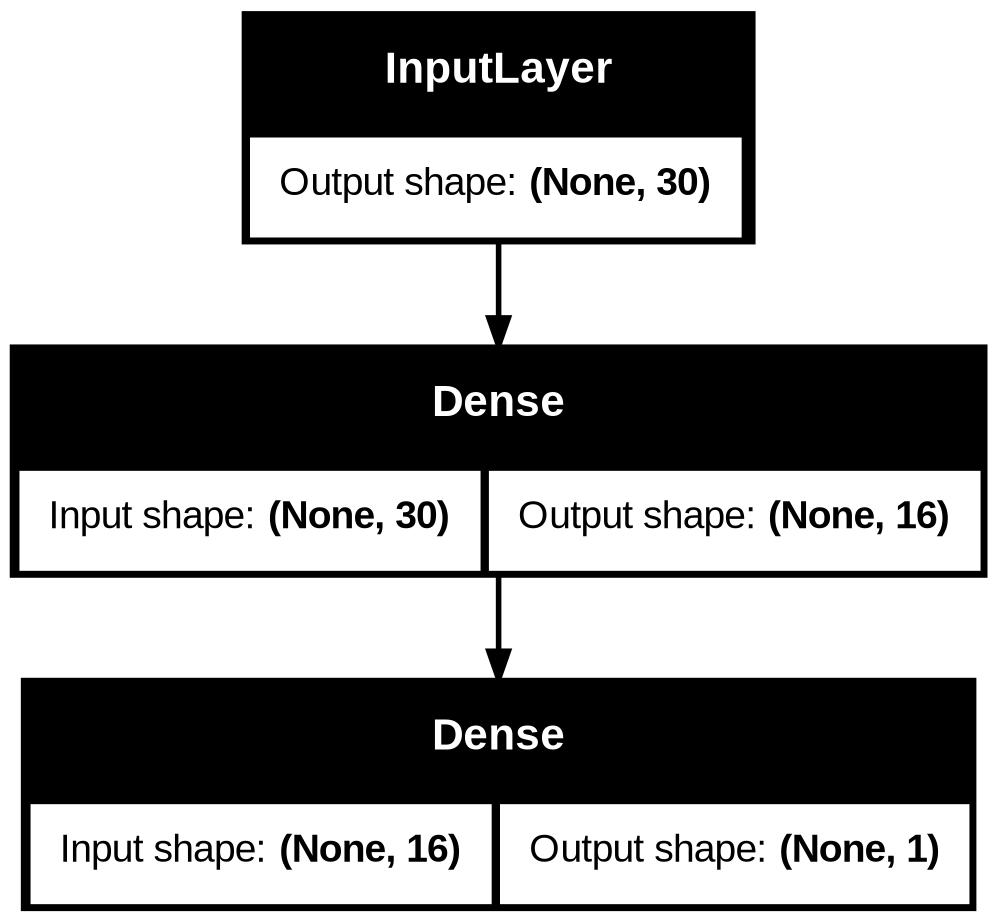

In [ ]:
keras.utils.plot_model(model, show_shapes=True) #graphical view of the neural network

In [ ]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [ ]:
history = model.fit(train_X, train_y, epochs=300, verbose='auto', batch_size=32, validation_split=0.2)

In [ ]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

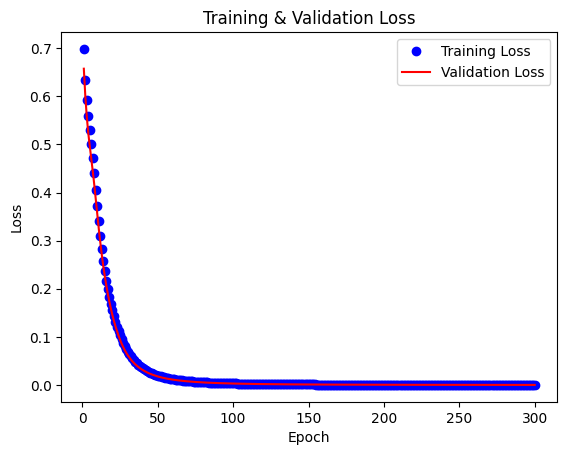

In [ ]:
loss_values = history_dict['loss']
validation_loss_values = history_dict['val_loss']
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, 'bo', label='Training Loss') #'bo' -> blue & 'o' for round {SHORTHAND FOR SETTING BOTH COLOR AND MARKER}
plt.plot(epochs, validation_loss_values, 'r', label='Validation Loss') #'r' -> Red
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

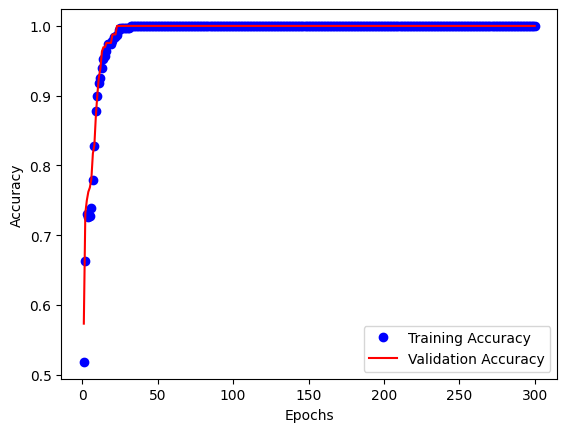

In [ ]:
validation_accuracy = history_dict['val_accuracy']
accuracy = history_dict['accuracy']

plt.plot(epochs, accuracy, 'bo', label='Training Accuracy')
plt.plot(epochs, validation_accuracy, 'r', label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

**HENCE NO CASE OF OVERFITTING LITERALLY!!!!!**

100% ACCURACY ACHIEVED LITERALLY. That's the power of Neural Networks

In [ ]:
pred_y = model.predict(test_X)